In [1]:
import re
from collections import Counter
from difflib import get_close_matches

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (AdaBoostClassifier, BaggingClassifier, ExtraTreesClassifier,
                              GradientBoostingClassifier, HistGradientBoostingClassifier,
                              RandomForestClassifier)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

In [2]:
# ===== SEMUA PENGATURAN ADA DI SINI. Cell lain tidak perlu diedit =====

# --- data ---
TRAIN_CSV = "data/train.csv"
TEST_CSV = ""                    # kosongkan bila file test tidak ada/rusak -> test dipotong sendiri dari TRAIN_CSV
TARGET = "Golongan UKT"          # kolom yang ditebak
KOLOM_ID = "id"                  # dipakai untuk submission, dibuang dari fitur
SEED = 42
BAGIAN_TEST = 0.2                # dipotong paling awal dari TRAIN_CSV, labelnya disembunyikan sampai akhir
BAGIAN_VALID = 0.2               # untuk pilih model/tuning; dua-duanya pecahan dari TOTAL data, stratified

# --- pembersihan ---
KOLOM_DIBUANG = [KOLOM_ID, "Kota", "Kepemilikan Aset", "Lokasi Tempat Tinggal"]
KOLOM_MATERIAL = ["Bahan Atap Rumah", "Bahan Tembok Rumah", "Bahan Lantai Rumah"]   # teks bebas -> flag 0/1 per kata
PENANDA_KOSONG = ["", "-", "--", "?", "nan", "null", "none", "n/a", "na", "tidak tahu"]
BATAS_PENJAGA = 2_000_000_000    # nilai >= ini dianggap kosong (2.147.483.647 = 2^31-1 dan variannya)
MAKS_KOSONG_FRAKSI = 0.46        # buang baris train yang kosongnya lebih dari ini (setara "11 dari 24 kolom")
ISI_TETAP = {"Status Kepesertaan Program Bantuan Pemerintah": "tidak"}   # huruf kecil, karena teks di-lowercase
PETA_NILAI = {"Pendidikan Orang Tua/Wali": {"sma": "slta", "sltp": "smp", "s- 2": "s-2", "d.1": "d-1", "s- 3": "s-3"}}

# --- fitur kata dari kolom material ---
MIN_FRAKSI_TOKEN = 0.01          # kata dipakai sebagai fitur bila muncul di >= 1% baris train
MIN_KEMIRIPAN = 0.85             # kata dianggap typo kata yang lebih sering muncul bila kemiripan >= ini
STOPWORD = {"dan", "atau", "yang", "dari", "dengan", "di"}
SINONIM = {   # varian umum yang tidak tertangkap fuzzy (karena sama-sama sering muncul)
    "genting": "genteng", "gendeng": "genteng", "kenteng": "genteng", "geteng": "genteng",
    "esbes": "asbes", "asbas": "asbes", "ternit": "eternit", "internit": "eternit",
    "kramik": "keramik", "kermik": "keramik", "keremik": "keramik",
    "tekel": "tegel", "tehel": "tegel", "teghel": "tegel",
    "plaster": "plester", "pelaster": "plester", "mester": "plester", "plesteran": "plester", "diplester": "plester",
    "herbel": "hebel", "habel": "hebel", "harbel": "hebel", "batubata": "bata",
    "galfalum": "galvalum", "spandex": "spandek", "multiruf": "multiroof",
}

# --- model ---
MIN_FREKUENSI_KATEGORI = 5       # kategori yang muncul < ini digabung jadi satu "jarang"
PILIH_MODEL = "xgboost"          # nama dari DAFTAR_MODEL di cell model
BANDINGKAN_MODEL = False         # True = adu semua model pakai cross-validation (lama)

In [8]:
'''Pipeline pembersihan. Jalankan dari atas ke bawah; setiap `# %%` adalah satu langkah.

Aturan: split dulu (test dipotong paling awal dan diperlakukan seperti file test tanpa label), lalu
statistik (kosakata kata material) dihitung dari train SAJA dan dipakai ke valid dan test; baris hanya
dibuang dari train (valid dan test tidak pernah dibuang). Label test baru dibuka di cell terakhir.
Daftar kolom angka/teks diturunkan dari data, jadi tidak ditulis tangan.'''


# %% fungsi bantu
def rapikan_teks(seri):
    """strip + rapikan spasi + huruf kecil + penanda kosong -> NaN."""
    teks = seri.astype(str).str.strip().str.replace(r"\s+", " ", regex=True).str.lower()
    return teks.where(seri.notna() & ~teks.isin(PENANDA_KOSONG))


def tokenisasi(teks):
    """'Genteng dan Asbes' -> ['genteng', 'asbes'] (sinonim sudah disatukan)."""
    if pd.isna(teks):
        return []
    kata = re.findall(r"[a-z0-9]+", str(teks).lower())
    return [SINONIM.get(k, k) for k in kata if k not in STOPWORD]


class FlagKata:
    """Teks bebas -> kolom 0/1 per kata umum. Kosakata dipelajari dari train saja;
    kata yang mirip kata lain yang lebih sering muncul dianggap typo-nya (fuzzy), jadi tidak perlu dict manual."""

    def __init__(self, awalan):
        self.awalan = awalan

    def fit(self, seri):
        hitung = Counter(k for teks in seri for k in set(tokenisasi(teks)))
        batas = max(2, int(MIN_FRAKSI_TOKEN * len(seri)))
        self._cache = {}
        kosakata = []
        for kata, n in hitung.most_common():          # dari yang paling sering
            if n < batas:
                break
            cocok = get_close_matches(kata, kosakata, n=1, cutoff=MIN_KEMIRIPAN)
            if cocok:
                self._cache[kata] = cocok[0]          # mirip kata yang lebih sering -> anggap typo-nya
            else:
                kosakata.append(kata)
        self.kosakata_ = sorted(kosakata)
        self.nama_kolom_ = [f"{self.awalan}: {k}" for k in self.kosakata_] + [f"{self.awalan}: kosong"]
        return self

    def _baku(self, kata):
        if kata not in self._cache:
            if kata in self.kosakata_:
                self._cache[kata] = kata
            else:
                cocok = get_close_matches(kata, self.kosakata_, n=1, cutoff=MIN_KEMIRIPAN)
                self._cache[kata] = cocok[0] if cocok else kata
        return self._cache[kata]

    def transform(self, seri):
        baris = []
        for teks in seri:
            kata = {self._baku(k) for k in tokenisasi(teks)}
            baris.append([int(k in kata) for k in self.kosakata_] + [int(pd.isna(teks))])
        return pd.DataFrame(baris, index=seri.index, columns=self.nama_kolom_, dtype=int)


# %% baca data + potong test sendiri
data = pd.read_csv(TRAIN_CSV)
if TEST_CSV:
    train_valid, test = data, pd.read_csv(TEST_CSV)
else:   # test sendiri: stratified, dipotong sebelum apa pun dihitung
    train_valid, test = train_test_split(data, test_size=BAGIAN_TEST, random_state=SEED, stratify=data[TARGET])
test = test.sort_index().copy()                                          # kembalikan urutan baris asli
test_label = test[TARGET].copy() if TARGET in test.columns else None     # disimpan, TIDAK dipakai sampai cell terakhir
test = test.drop(columns=[TARGET], errors="ignore")                      # dari sini test = file tanpa label
id_test = test[KOLOM_ID].copy() if KOLOM_ID in test.columns else None    # disimpan sebelum id dibuang


# %% split data
# sisa data dibagi train/valid, stratified; statistik langkah sesudah ini dari train saja
train, valid = train_test_split(train_valid, test_size=round(BAGIAN_VALID * len(data)),
                                random_state=SEED, stratify=train_valid[TARGET])
train, valid = train.sort_index().copy(), valid.sort_index().copy()   # kembalikan urutan baris asli
print("train", train.shape, "valid", valid.shape, "test", test.shape)


# %% langkah 1: buang kolom
train, valid, test = [df.drop(columns=KOLOM_DIBUANG, errors="ignore") for df in (train, valid, test)]


# %% langkah 2: rapikan teks + penanda kosong (semua kolom teks, otomatis dari dtype)
KOLOM_TEKS = [k for k in train.select_dtypes(exclude="number").columns if k != TARGET]
for df in (train, valid, test):
    for kolom in KOLOM_TEKS:
        df[kolom] = rapikan_teks(df[kolom])


# %% langkah 3: nilai penjaga -> kosong (semua kolom angka, otomatis dari dtype)
KOLOM_ANGKA = [k for k in train.select_dtypes(include="number").columns if k != TARGET]
for df in (train, valid, test):
    df[KOLOM_ANGKA] = df[KOLOM_ANGKA].mask(df[KOLOM_ANGKA] >= BATAS_PENJAGA)


# %% langkah 4: isi nilai tetap + satukan ejaan (peta kecil)
for df in (train, valid, test):
    df.fillna(ISI_TETAP, inplace=True)
    for kolom, peta in PETA_NILAI.items():
        df[kolom] = df[kolom].replace(peta)


# %% langkah 5: buang duplikat (train)
sebelum = len(train)
train = train.drop_duplicates()
print("duplikat dibuang:", sebelum - len(train))


# %% langkah 6: buang baris banyak kosong (train)
sebelum = len(train)
train = train[train.isna().mean(axis=1) <= MAKS_KOSONG_FRAKSI].copy()
print("baris terlalu banyak kosong dibuang:", sebelum - len(train))


# %% langkah 7: kolom material (teks bebas) -> flag kata, kosakata dari train
flag_material = {k: FlagKata(k).fit(train[k]) for k in KOLOM_MATERIAL}


def pasang_flag(df):
    bagian = [flag_material[k].transform(df[k]) for k in KOLOM_MATERIAL]
    return pd.concat([df.drop(columns=KOLOM_MATERIAL)] + bagian, axis=1)


train, valid, test = [pasang_flag(df) for df in (train, valid, test)]
KOLOM_FLAG = [n for f in flag_material.values() for n in f.nama_kolom_]
print({k: len(f.kosakata_) for k, f in flag_material.items()}, "<- jumlah kata per kolom material")


# %% langkah 8: daftar kolom final (diturunkan dari data)
NUM_COLS = [k for k in train.select_dtypes(include="number").columns if k != TARGET]   # angka asli + flag
CAT_COLS = list(train.select_dtypes(exclude="number").columns)
FITUR = NUM_COLS + CAT_COLS
kurang = set(FITUR) - set(test.columns)
assert not kurang, f"kolom ini ada di train tapi tidak ada di test: {kurang}"
print("angka:", len(NUM_COLS), "(termasuk", len(KOLOM_FLAG), "flag) | kategori:", len(CAT_COLS))


# %% simpan
print("train", train.shape, "valid", valid.shape, "test", test.shape)
train.to_csv("train_bersih.csv", index=False)
valid.to_csv("valid_bersih.csv", index=False)
test.to_csv("test_bersih.csv", index=False)

train (18228, 28) valid (6076, 28) test (6076, 27)
duplikat dibuang: 9
baris terlalu banyak kosong dibuang: 58
{'Bahan Atap Rumah': 7, 'Bahan Tembok Rumah': 13, 'Bahan Lantai Rumah': 6} <- jumlah kata per kolom material
angka: 39 (termasuk 29 flag) | kategori: 10
train (18161, 50) valid (6076, 50) test (6076, 49)


Golongan UKT
4.0    0.218435
0.0    0.183635
3.0    0.167997
5.0    0.157150
6.0    0.098398
7.0    0.093938
2.0    0.076317
1.0    0.004130
Name: proportion, dtype: float64


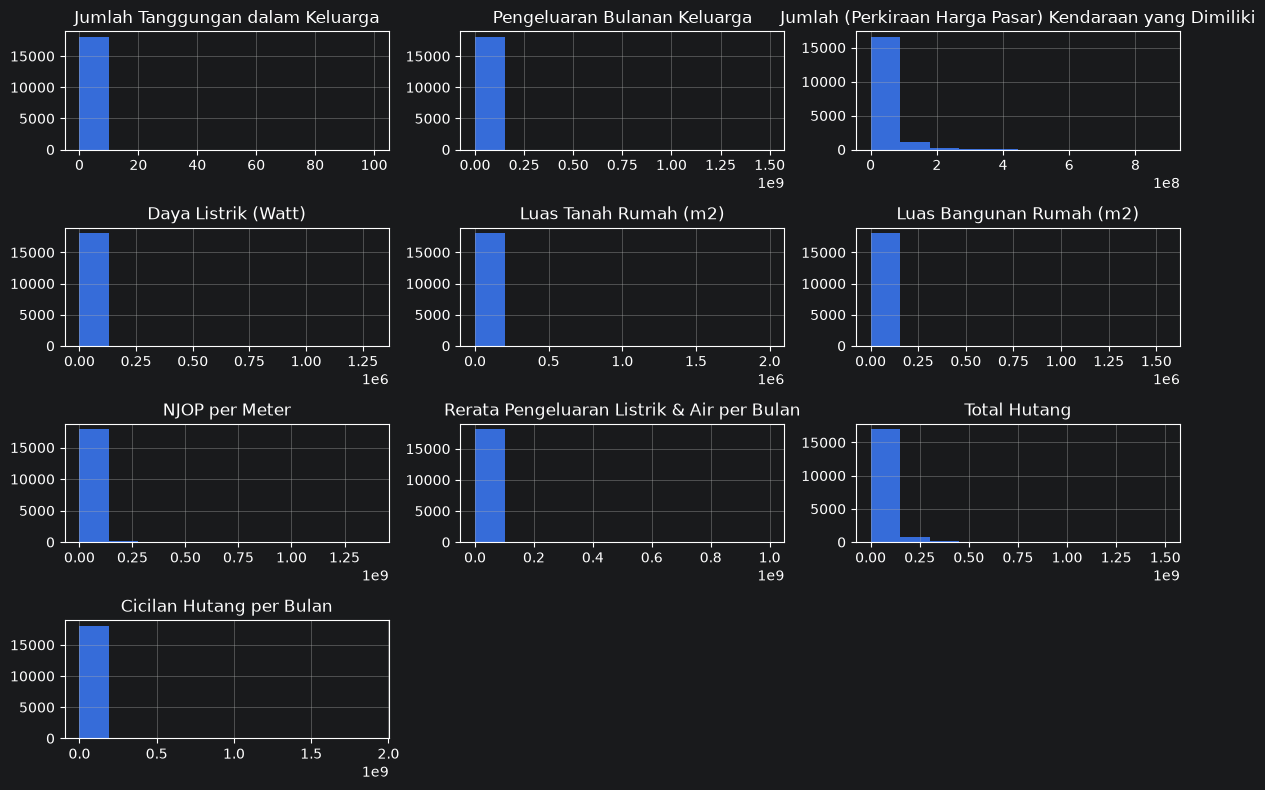

                                    mean  count
Pendapatan Keluarga                            
lebih dari rp 5.000.000         5.579353   5066
rp 1.000.000 s.d. rp 2.000.000  2.141604   4103
rp 2.000.000 s.d. rp 3.000.000  2.729154   3382
rp 3.000.000 s.d. rp 4.000.000  3.517241   2349
kurang dari rp 1.000.000,-      2.055758   1650
rp 4.000.000 s.d. rp 5.000.000  4.294194   1533 

                              mean  count
Pekerjaan Orang Tua/Wali                 
wiraswasta                3.629630   4158
buruh                     2.451555   3922
pegawai swasta            4.468720   3085
pegawai pemerintahan      5.572023   2402
tidak bekerja             3.006846   2337
petani                    2.584490   2089
nelayan                   2.660194    103 

                               mean  count
Pendidikan Orang Tua/Wali                 
slta                       3.502233   3582
slta sederajat             3.486957   1840
ma                         3.560046   1757
smp                

In [9]:
print(train[TARGET].value_counts(normalize=True))

NUM_ASLI = [k for k in NUM_COLS if k not in KOLOM_FLAG]      # flag 0/1 tidak perlu di-histogram
train[NUM_ASLI].hist(figsize=(12, 8))
plt.tight_layout()
plt.show()

for col in CAT_COLS:
    ringkas = train.groupby(col)[TARGET].agg(["mean", "count"]).sort_values("count", ascending=False)
    print(ringkas.head(15), "\n")

In [10]:
X_train, y_train = train[FITUR], train[TARGET]
X_val, y_val = valid[FITUR], valid[TARGET]

# label diubah ke 0..k-1 supaya semua model (XGBoost dkk) aman; hasil prediksi dikembalikan ke label asli
le = LabelEncoder().fit(y_train)
y_train_enc = le.transform(y_train)

print("train:", X_train.shape, "| valid:", X_val.shape)

train: (18161, 49) | valid: (6076, 49)


In [11]:
num_steps = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
cat_steps = make_pipeline(SimpleImputer(strategy="most_frequent"),
                          OneHotEncoder(handle_unknown="infrequent_if_exist",
                                        min_frequency=MIN_FREKUENSI_KATEGORI, sparse_output=False))
preprocess = ColumnTransformer([
    ("num", num_steps, NUM_COLS),
    ("cat", cat_steps, CAT_COLS),
])

DAFTAR_MODEL = {
    "logreg": LogisticRegression(C=1.0, max_iter=2000),                       # cepat, mudah dijelaskan
    "random_forest": RandomForestClassifier(n_estimators=500, random_state=SEED),
    "extra_trees": ExtraTreesClassifier(n_estimators=500, random_state=SEED),
    "hist_gb": HistGradientBoostingClassifier(random_state=SEED),
    "lightgbm": LGBMClassifier(n_estimators=500, learning_rate=0.03, random_state=SEED, verbose=-1),
    "xgboost": XGBClassifier(n_estimators=500, learning_rate=0.03, random_state=SEED),
    "catboost": CatBoostClassifier(iterations=500, random_seed=SEED, verbose=0),
    "svc": SVC(C=1.0, random_state=SEED),
    "knn": KNeighborsClassifier(n_neighbors=15),
    "decision_tree": DecisionTreeClassifier(max_depth=6, random_state=SEED),
    "gradient_boosting": GradientBoostingClassifier(random_state=SEED),
    "adaboost": AdaBoostClassifier(n_estimators=300, random_state=SEED),
    "bagging": BaggingClassifier(n_estimators=100, random_state=SEED),
    "ridge": RidgeClassifier(alpha=1.0),
    "mlp": MLPClassifier(hidden_layer_sizes=(64,), max_iter=1000, random_state=SEED),
}


def prediksi(pipe, X):
    """prediksi -> label asli (np.ravel karena CatBoost mengembalikan array 2 dimensi)."""
    return le.inverse_transform(np.ravel(pipe.predict(X)).astype(int))


if BANDINGKAN_MODEL:   # opsional: adu semua model, urut dari F1 macro tertinggi
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    hasil = {}
    for nama, m in DAFTAR_MODEL.items():
        skor = cross_val_score(make_pipeline(preprocess, m), X_train, y_train_enc,
                               cv=cv, scoring="f1_macro", n_jobs=-1)
        hasil[nama] = {"f1_macro": skor.mean(), "std": skor.std()}
        print(nama, round(skor.mean(), 4))
    print(pd.DataFrame(hasil).T.sort_values("f1_macro", ascending=False).round(4))

pipe = make_pipeline(preprocess, DAFTAR_MODEL[PILIH_MODEL])
pipe.fit(X_train, y_train_enc)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('xgbclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](8,)","[0,1,2,...,5,6,7]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](49,)","['Jumlah Tanggungan dalam Keluarga','Pengeluaran Bulanan Keluarga', 'Jumlah (Perkiraan Harga Pasar) Kendaraan yang Dimiliki',..., 'Status Kepemilikan Tempat Tinggal','Program Studi','Jalur Masuk']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,49
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretra

F1 macro: 0.419
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      1111
         1.0       0.00      0.00      0.00        25
         2.0       0.42      0.20      0.27       462
         3.0       0.44      0.47      0.46      1017
         4.0       0.42      0.53      0.47      1324
         5.0       0.36      0.33      0.34       952
         6.0       0.31      0.23      0.26       597
         7.0       0.52      0.58      0.55       588

    accuracy                           0.52      6076
   macro avg       0.43      0.42      0.42      6076
weighted avg       0.52      0.52      0.51      6076



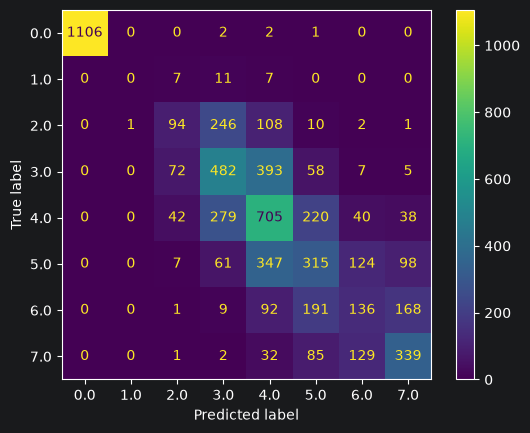

In [12]:
val_predictions = prediksi(pipe, X_val)
print("F1 macro:", round(f1_score(y_val, val_predictions, average="macro"), 4))
print(classification_report(y_val, val_predictions, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_val, val_predictions)
plt.show()

Golongan UKT
0    1107
1       2
2     235
3    1127
4    1651
5     865
6     426
7     663
Name: count, dtype: int64
F1 macro TEST: 0.4268
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      1111
         1.0       0.00      0.00      0.00        25
         2.0       0.44      0.23      0.30       462
         3.0       0.44      0.49      0.47      1018
         4.0       0.41      0.52      0.46      1323
         5.0       0.36      0.32      0.34       952
         6.0       0.31      0.22      0.26       597
         7.0       0.56      0.63      0.59       588

    accuracy                           0.53      6076
   macro avg       0.44      0.43      0.43      6076
weighted avg       0.52      0.53      0.52      6076



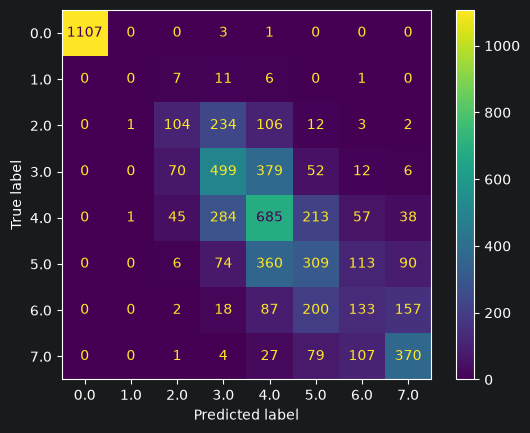

In [13]:
# prediksi test (file test hasil potongan sendiri). Dijalankan sekali, SETELAH model final dipilih;
# jangan balik ke cell model gara-gara skor di sini, nanti test ikut "dipakai" untuk memilih
test_predictions = prediksi(pipe, test[FITUR]).astype(int)   # hapus .astype(int) bila label berupa teks
submission = pd.DataFrame({KOLOM_ID: id_test.values, TARGET: test_predictions})
submission.to_csv("submission.csv", index=False)
print(submission[TARGET].value_counts().sort_index())

if test_label is not None:   # label asli test baru dibuka di sini
    print("F1 macro TEST:", round(f1_score(test_label, test_predictions, average="macro"), 4))
    print(classification_report(test_label, test_predictions, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(test_label, test_predictions)
    plt.show()